# SynthFace on Google Colab: 3D synthetic identities (approach A)

Renders many synthetic identities with **Blender 5.2.2 + MPFB 2.0.17** (same versions and assets as the dev
laptop, every download sha256-checked) on the Colab **GPU**. Same seed gives the same identities as on the laptop.

**Before you start**
1. `Runtime > Change runtime type > T4 GPU` (or better).
2. Nothing to set up for the code: it is cloned from the public GitHub repo (no token).
3. Run the cells top to bottom. Output goes to Google Drive (`DRIVE_DIR`) so a disconnect loses nothing;
   re-running the render cell resumes where it stopped.

Rules (CLAUDE.md): license-clean assets only (all already in `assets/LICENSES.csv`), no AI-generated faces here,
never commit `output/`.

## 1. Settings

In [1]:
JOB_ID = "colab_20x10"          # new name for every new batch
SEED = 20261013                 # same seed + same settings = same identities
NUM_IDENTITIES = 20
IMAGES_PER_IDENTITY = 10
SAMPLES = 48                    # Cycles samples (+ denoiser)
DEVICE = "OPTIX"                # "OPTIX" (T4/L4/A100), "CUDA" if OptiX fails, "CPU" without GPU
REPO = "https://github.com/ankitscode/-synthetic-Image-Genrator.git"   # public, no token needed
BRANCH = "master"               # master = 3D pipeline
DRIVE_DIR = "/content/drive/MyDrive/synthface_output"   # None = keep output only in this VM

PROJECT = "/content/synthface"
TOOLS = "/content/synthface_tools"
BLENDER = f"{TOOLS}/blender-5.2.2-linux-x64/blender"

## 2. Check the GPU

In [2]:
!nvidia-smi -L || echo "No GPU: Runtime > Change runtime type > T4 GPU (or set DEVICE = 'CPU', very slow)"

GPU 0: Tesla T4 (UUID: GPU-1b806ebc-65aa-4213-7e9b-34a0b78c2957)


## 3. Mount Drive and clone the public GitHub repo

In [3]:
import os, subprocess

if DRIVE_DIR:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)

if not os.path.isdir(PROJECT):
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO, PROJECT], check=True)
else:
    subprocess.run(["git", "-C", PROJECT, "pull", "--ff-only"], check=True)
print(subprocess.run(["git", "-C", PROJECT, "log", "--oneline", "-1"], capture_output=True, text=True).stdout)


Mounted at /content/drive
4e9eb24 Colab: clone from the public GitHub mirror (no token)



## 4. Install Blender, MPFB, asset packs and HDRIs (about 3-5 min)

In [4]:
!bash {PROJECT}/colab/setup_colab.sh {TOOLS}


== system libraries for headless Blender
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)

== downloads (sha256 checked)
######################################################################## 100.0%
ok blender-5.2.2-linux-x64.tar.xz
######################################################################## 100.0%
ok add-on-mpfb-v2.0.17.zip
######################################################################## 100.0%
ok makehuman_system_assets_cc0.zip
######################################################################## 100.0%
ok skins01_cc0.zip
######################################################################## 100.0%
ok skins02_cc0.zip

== Blender 5.2.2
Blender 5.2.2 LTS

== MPFB 2.0.17 -> /root/.config/blender/5.2/extensions/blender_org/mpfb

== MakeHuman asset packs -> /root/.config/blender/5.2/extensions/.user/blender_org/mpfb/data



## 5. Send output to Drive (optional)

In [5]:
out = f"{PROJECT}/output"
if DRIVE_DIR and not os.path.islink(out):
    if os.path.isdir(out) and os.listdir(out):
        raise SystemExit(f"{out} already has files; move them first")
    if os.path.isdir(out):
        os.rmdir(out)
    os.symlink(DRIVE_DIR, out)
os.makedirs(out, exist_ok=True)
print(out, "->", os.path.realpath(out))

/content/synthface/output -> /content/drive/MyDrive/synthface_output


## 6. Render the identities

Prints one line per finished identity. Safe to re-run after a disconnect (`--resume` skips finished identities).
Blender's log is in `output/<JOB_ID>/blender_stderr.log`.

In [6]:
import json, time

job_dir = f"{PROJECT}/output/{JOB_ID}"
os.makedirs(job_dir, exist_ok=True)
job = {"job_id": JOB_ID, "seed": SEED, "num_identities": NUM_IDENTITIES,
       "images_per_identity": IMAGES_PER_IDENTITY, "render": {"samples": SAMPLES, "device": DEVICE}}
job_path = f"{job_dir}/job.json"
if os.path.exists(job_path):
    if json.load(open(job_path)) != job:
        raise SystemExit(f"{job_path} exists with other settings: use a new JOB_ID")
else:
    json.dump(job, open(job_path, "w"), indent=2)

cmd = [BLENDER, "--background", "--python", "blender/render_batch.py", "--", "--job", job_path, "--resume"]
t0 = time.time()
with open(f"{job_dir}/blender_stderr.log", "a") as err:
    proc = subprocess.Popen(cmd, cwd=PROJECT, stdout=subprocess.PIPE, stderr=err, text=True)
    for line in proc.stdout:
        if line.startswith('{"event"'):
            ev = json.loads(line)
            note = " (already done)" if ev.get("skipped") else ""
            print(f"identity {ev['index']}/{NUM_IDENTITIES} {ev['status']}{note}  {time.time() - t0:.0f}s", flush=True)
print("Blender exit code:", proc.wait())

identity 1/20 done  42s
identity 2/20 done  79s
identity 3/20 done  112s
identity 4/20 done  148s
identity 5/20 done  185s
identity 6/20 done  223s
identity 7/20 done  257s
identity 8/20 done  295s
identity 9/20 done  329s
identity 10/20 done  366s
identity 11/20 done  402s
identity 12/20 done  437s
identity 13/20 done  474s
identity 14/20 done  510s
identity 15/20 done  547s
identity 16/20 done  579s
identity 17/20 done  612s
identity 18/20 done  648s
identity 19/20 done  683s
identity 20/20 done  719s
Blender exit code: 0


## 7. Contact sheet (one row per identity)

INFO Wrote output/colab_20x10/contact_sheet.png (1475x2622)


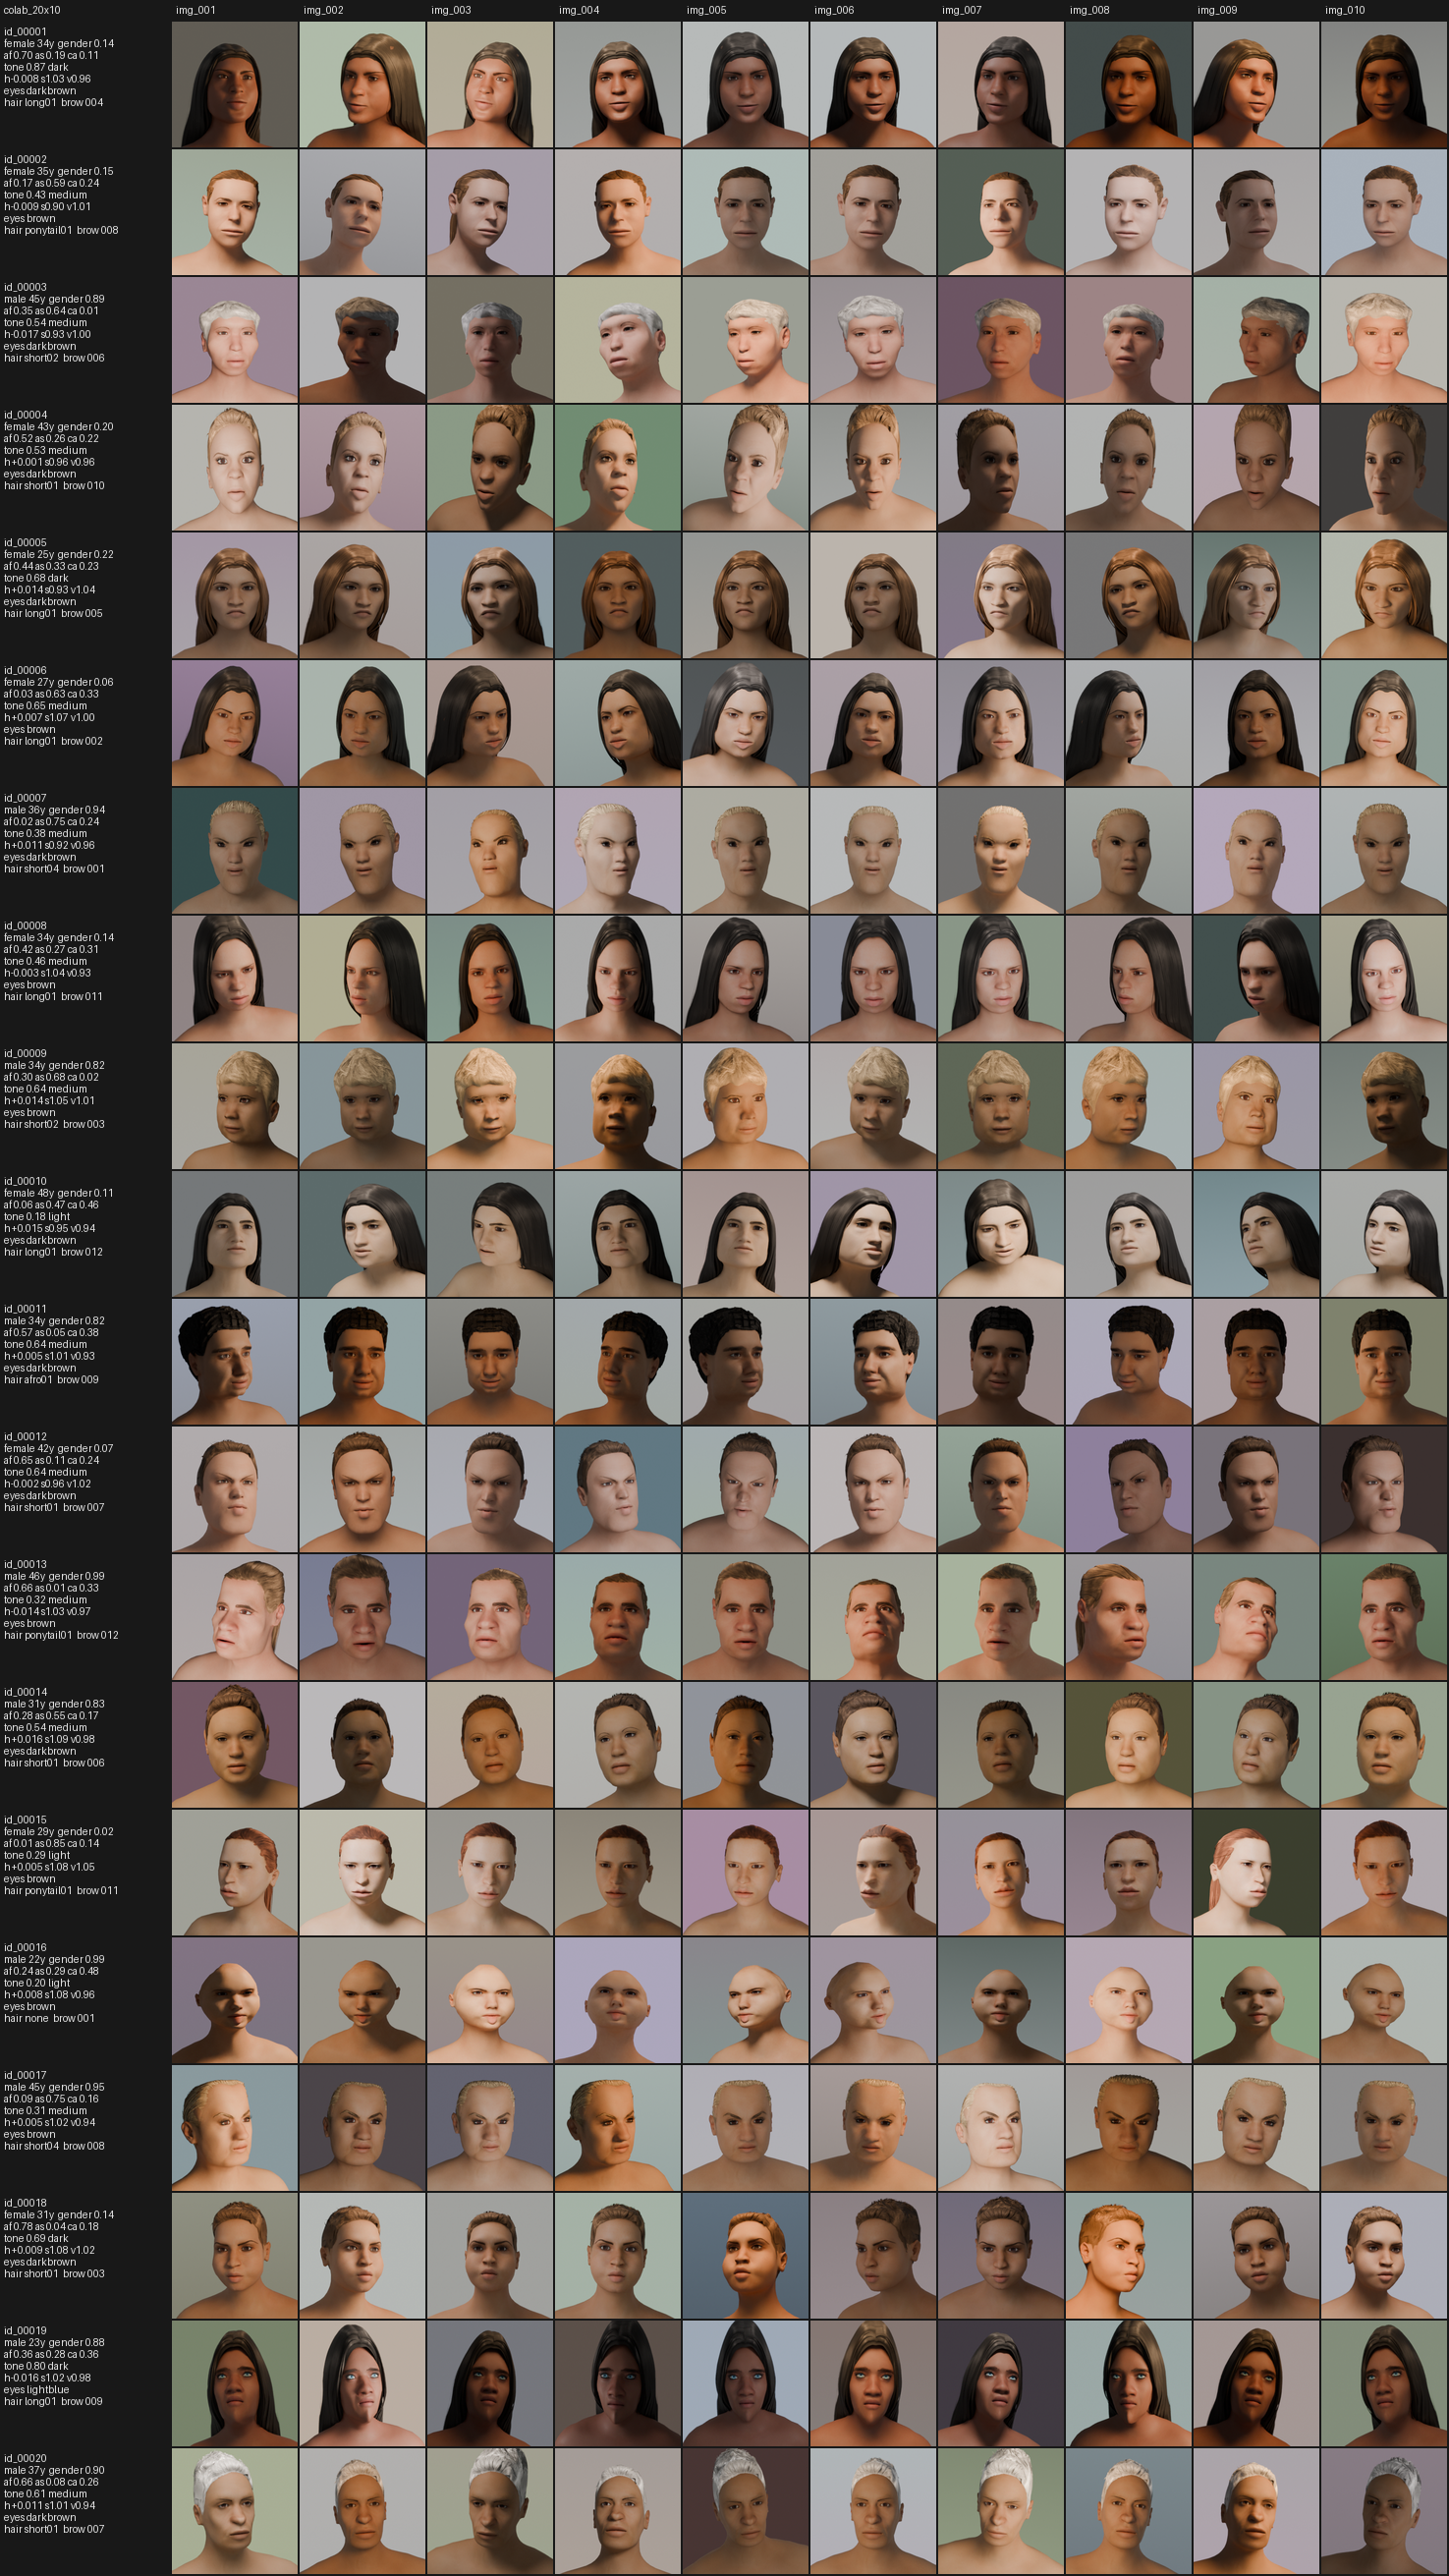

In [7]:
!cd {PROJECT} && python tools/contact_sheet.py output/{JOB_ID} --max-cols 10
from IPython.display import Image, display
display(Image(f"{job_dir}/contact_sheet.png"))

## 8. Bring the batch back to the laptop

- With Drive: it is already in `MyDrive/synthface_output/<JOB_ID>/`. Download that folder.
- Without Drive: run the cell below to download a zip.

On the laptop, unzip to `output/<JOB_ID>/` in the project, then review with
`venv/bin/python tools/contact_sheet.py output/<JOB_ID>`.

In [8]:
import shutil
from google.colab import files
zip_path = shutil.make_archive(f"/content/{JOB_ID}", "zip", job_dir)
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>